In [1]:
# Trabalho teórico/computacional - Maximização da probabilidade a posteriori

In [5]:
# importando as bibliotecas
import pandas as pd
import io
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

In [6]:
# visualizando o csv (necessario por conta das linhas de atributos no comeco do dataset)

# carregando o arquivo 
caminho = "dataset-trab3/dataset.csv"

atributos = []
linhas_dados = []
data_iniciada = False

with open(caminho, 'r', encoding='utf-8') as f:
    for linha in f:
        # Remove o número da linha prefixado (ex: "44,7590-VHVEG...")
        partes = linha.split(',', 1)
        if len(partes) == 2:
            conteudo = partes[1].strip()
            
            # Identifica as colunas/atributos
            if conteudo.startswith('@ATTRIBUTE'):
                atributos.append(conteudo.split()[1])
            # Identifica o início dos dados
            elif conteudo == '@DATA':
                data_iniciada = True
            # Coleciona apenas as linhas de dados reais
            elif data_iniciada and conteudo:
                linhas_dados.append(conteudo)

# 2. Construção do DataFrame
dados_csv = '\n'.join(linhas_dados)
df = pd.read_csv(io.StringIO(dados_csv), header=None, names=atributos)

# 3. Conversão de tipos numéricos
df['tenure'] = pd.to_numeric(df['tenure'], errors='coerce')
df['MonthlyCharges'] = pd.to_numeric(df['MonthlyCharges'], errors='coerce')
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Exibe as primeiras 5 linhas para confirmar que foi lido corretamente
df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


--- RESULTADOS DA QUESTÃO 1 ---
Número de amostras (N): 7043
Média Amostral / Máxima Verossimilhança (mu_MV): 64.7617 €/$
Variância Amostral (sigma^2): 905.4109

Prior sigma_mu^2 =  5 | w = 0.974934 | mu_MAP = 64.6423
Prior sigma_mu^2 = 10 | w = 0.987308 | mu_MAP = 64.7013
Prior sigma_mu^2 = 20 | w = 0.993613 | mu_MAP = 64.7313
Prior sigma_mu^2 = 50 | w = 0.997435 | mu_MAP = 64.7495


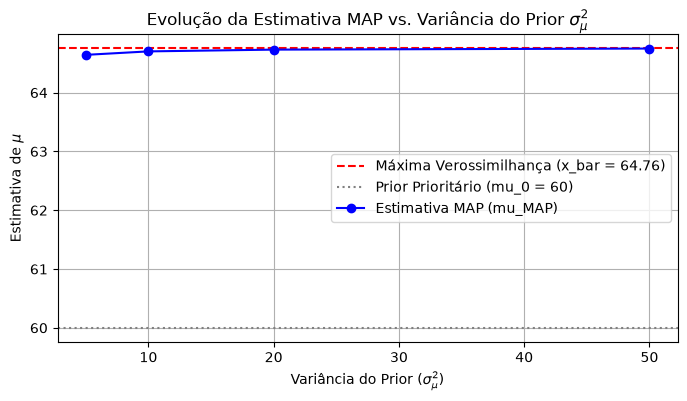

In [7]:
# --- QUESTÃO 1 ---
monthly = df['MonthlyCharges'].dropna().values
N = len(monthly)
x_bar = np.mean(monthly) # Estimativa de Máxima Verossimilhança (MV)
sigma2 = np.var(monthly, ddof=1) # Variância amostral dada pelos dados

mu_0 = 60
variancias_prior = [5, 10, 20, 50]

print(f"--- RESULTADOS DA QUESTÃO 1 ---")
print(f"Número de amostras (N): {N}")
print(f"Média Amostral / Máxima Verossimilhança (mu_MV): {x_bar:.4f} €/$")
print(f"Variância Amostral (sigma^2): {sigma2:.4f}\n")

resultados_map = []
for sigma2_mu in variancias_prior:
    w = (N * sigma2_mu) / (N * sigma2_mu + sigma2)
    mu_map = w * x_bar + (1 - w) * mu_0
    resultados_map.append({'sigma2_mu': sigma2_mu, 'mu_MAP': mu_map, 'peso_w': w})
    print(f"Prior sigma_mu^2 = {sigma2_mu:2d} | w = {w:.6f} | mu_MAP = {mu_map:.4f}")

# Gráfico comparativo
plt.figure(figsize=(8, 4))
plt.axhline(x_bar, color='red', linestyle='--', label=f'Máxima Verossimilhança (x_bar = {x_bar:.2f})')
plt.axhline(mu_0, color='gray', linestyle=':', label=f'Prior Prioritário (mu_0 = {mu_0})')

sigmas = [r['sigma2_mu'] for r in resultados_map]
mus = [r['mu_MAP'] for r in resultados_map]

plt.plot(sigmas, mus, 'o-', color='blue', label='Estimativa MAP (mu_MAP)')
plt.xlabel(r'Variância do Prior ($\sigma_\mu^2$)')
plt.ylabel(r'Estimativa de $\mu$')
plt.title(r'Evolução da Estimativa MAP vs. Variância do Prior $\sigma_\mu^2$')
plt.legend()
plt.grid(True)
plt.show()

In [8]:
# --- QUESTÃO 2 ---

# Preparação dos atributos (G: tenure, T: MonthlyCharges -> U: TotalCharges)
df_reg = df[['tenure', 'MonthlyCharges', 'TotalCharges']].dropna()
X = df_reg[['tenure', 'MonthlyCharges']].values
y = df_reg['TotalCharges'].values

# Divisão Treino (80%) e Teste (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Ajuste do modelo OLS (Máxima Verossimilhança)
modelo_ols = LinearRegression()
modelo_ols.fit(X_train, y_train)

y_pred_train = modelo_ols.predict(X_train)
y_pred_test = modelo_ols.predict(X_test)

mse_train = mean_squared_error(y_train, y_pred_train)
mse_test = mean_squared_error(y_test, y_pred_test)

print("--- RESULTADOS DA QUESTÃO 2 (OLS / Máxima Verossimilhança) ---")
print(f"Coeficiente Tenure (w_1): {modelo_ols.coef_[0]:.4f}")
print(f"Coeficiente MonthlyCharges (w_2): {modelo_ols.coef_[1]:.4f}")
print(f"Intercepto (w_0): {modelo_ols.intercept_:.4f}")
print(f"Erro Quadrático Médio (MSE) - Treino: {mse_train:.4f}")
print(f"Erro Quadrático Médio (MSE) - Teste : {mse_test:.4f}")

--- RESULTADOS DA QUESTÃO 2 (OLS / Máxima Verossimilhança) ---
Coeficiente Tenure (w_1): 65.3447
Coeficiente MonthlyCharges (w_2): 35.7110
Intercepto (w_0): -2148.0480
Erro Quadrático Médio (MSE) - Treino: 545570.6100
Erro Quadrático Médio (MSE) - Teste : 514283.5023


--- RESULTADOS DA QUESTÃO 3 (Regressão MAP / Ridge) ---
Prior sigma_w^2 =  1 (alpha = 545570.6) | Coefs: [56.77, 33.83] | Intercepto: -1748.95 | MSE Treino: 598964.24 | MSE Teste: 576962.08
Prior sigma_w^2 =  2 (alpha = 272785.3) | Coefs: [60.73, 34.78] | Intercepto: -1938.95 | MSE Treino: 560716.29 | MSE Teste: 534290.99
Prior sigma_w^2 =  5 (alpha = 109114.1) | Coefs: [63.41, 35.35] | Intercepto: -2061.93 | MSE Treino: 548198.21 | MSE Teste: 518910.12
Prior sigma_w^2 = 10 (alpha = 54557.1) | Coefs: [64.36, 35.53] | Intercepto: -2104.56 | MSE Treino: 546246.12 | MSE Teste: 515967.67


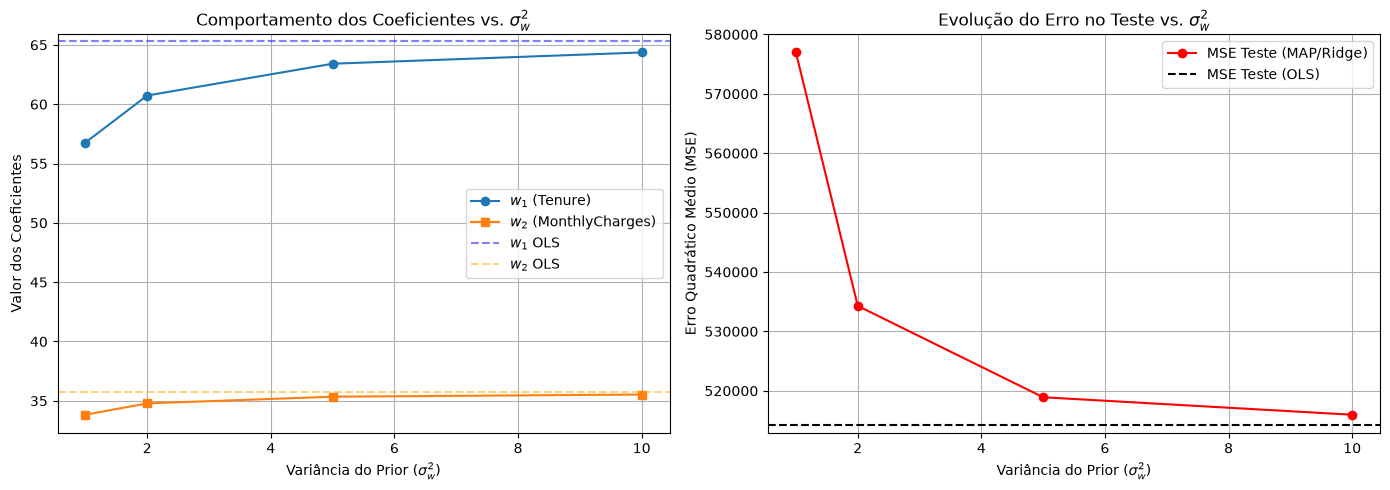

In [9]:
# --- QUESTÃO 3 ---
from sklearn.linear_model import Ridge

# Estimativa da variância do ruído dos dados sigma_e^2 a partir do erro residual do treino
sigma_e2 = mse_train 

sigma_w2_list = [1, 2, 5, 10]
res_ridge = []

print("--- RESULTADOS DA QUESTÃO 3 (Regressão MAP / Ridge) ---")
for s2_w in sigma_w2_list:
    # Correlação entre hiperparâmetro Ridge alpha e variância do prior sigma_w^2
    alpha = sigma_e2 / s2_w
    
    ridge = Ridge(alpha=alpha, fit_intercept=True)
    ridge.fit(X_train, y_train)
    
    y_tr_pred = ridge.predict(X_train)
    y_te_pred = ridge.predict(X_test)
    
    mse_tr = mean_squared_error(y_train, y_tr_pred)
    mse_te = mean_squared_error(y_test, y_te_pred)
    
    res_ridge.append({
        'sigma_w2': s2_w,
        'alpha': alpha,
        'coef': ridge.coef_,
        'intercept': ridge.intercept_,
        'mse_train': mse_tr,
        'mse_test': mse_te
    })
    
    print(f"Prior sigma_w^2 = {s2_w:2d} (alpha = {alpha:.1f}) | Coefs: [{ridge.coef_[0]:.2f}, {ridge.coef_[1]:.2f}] | Intercepto: {ridge.intercept_:.2f} | MSE Treino: {mse_tr:.2f} | MSE Teste: {mse_te:.2f}")

# Gráfico da evolução dos coeficientes e erros
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Variação dos Coeficientes
sigmas_w = [r['sigma_w2'] for r in res_ridge]
w1 = [r['coef'][0] for r in res_ridge]
w2 = [r['coef'][1] for r in res_ridge]

ax[0].plot(sigmas_w, w1, 'o-', label=r'$w_1$ (Tenure)')
ax[0].plot(sigmas_w, w2, 's-', label=r'$w_2$ (MonthlyCharges)')
ax[0].axhline(modelo_ols.coef_[0], color='blue', linestyle='--', alpha=0.5, label=r'$w_1$ OLS')
ax[0].axhline(modelo_ols.coef_[1], color='orange', linestyle='--', alpha=0.5, label=r'$w_2$ OLS')
ax[0].set_xlabel(r'Variância do Prior ($\sigma_w^2$)')
ax[0].set_ylabel('Valor dos Coeficientes')
ax[0].set_title(r'Comportamento dos Coeficientes vs. $\sigma_w^2$')
ax[0].legend()
ax[0].grid(True)

# Plot 2: Evolução do MSE no Teste
mse_tests = [r['mse_test'] for r in res_ridge]
ax[1].plot(sigmas_w, mse_tests, 'o-', color='red', label='MSE Teste (MAP/Ridge)')
ax[1].axhline(mse_test, color='black', linestyle='--', label='MSE Teste (OLS)')
ax[1].set_xlabel(r'Variância do Prior ($\sigma_w^2$)')
ax[1].set_ylabel('Erro Quadrático Médio (MSE)')
ax[1].set_title(r'Evolução do Erro no Teste vs. $\sigma_w^2$')
ax[1].legend()
ax[1].grid(True)

plt.tight_layout()
plt.show()